# 6.2N-Gram及自定义分类器

In [1]:
import os, random, operator, sys
from collections import Counter
import random
import collections
import math
import sys

import re
import numpy as np
from tqdm import tqdm
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import pandas as pd

## 一些功能函数
需要阅读这些函数来对实验中用到的数据结构，步骤有一些理解

In [2]:
def dotProduct(d1, d2):
    """
    @param dict d1: a feature vector represented by a mapping from a feature (string) to a weight (float).
    @param dict d2: same as d1
    @return float: the dot product between d1 and d2
    """
    if len(d1) < len(d2):
        return dotProduct(d2, d1)
    else:
        return sum(d1.get(f, 0) * v for f, v in d2.items())


In [3]:
def increment(d1, scale, d2):
    """
    Implements d1 += scale * d2 for sparse vectors.
    @param dict d1: the feature vector which is mutated.
    @param float scale
    @param dict d2: a feature vector.
    """
    for f, v in d2.items():
        d1[f] = d1.get(f, 0) + v * scale


In [4]:
def pre_data(x):
    '''
    处理“ISO 8859-1” 的控制字符（0x80-0x9F）和文字符号（0xA0-0xFF）。
    '''
    x = re.sub(r'[\u00BD]+', r'one half', x)    #  换为one half

    x = re.sub(r'[\u00C8-\u00CB]+', r'E', x)    #  换为E
    x = re.sub(r'[\u00D9-\u00DC]+', r'U', x)    #  换为U

    x = re.sub(r'[\u00E0-\u00E5]+', r'a', x)    #  换为a
    x = re.sub(r'[\u00E6]+', r'ae', x)          #  换为ae
    x = re.sub(r'[\u00E7]+', r'c', x)           #  换为e
    x = re.sub(r'[\u00E8-\u00EB]+', r'e', x)    #  换为e
    x = re.sub(r'[\u00EC-\u00EF]+', r'i', x)    #  换为i
    x = re.sub(r'[\u00F0]+', r'eth', x)         #  换为eth
    x = re.sub(r'[\u00F1]+', r'n', x)           #  换为n
    x = re.sub(r'[\u00F2-\u00F6]+', r'o', x)    #  换为o
    x = re.sub(r'[\u00F9-\u00FC]+', r'u', x)    #  换为u
    x = re.sub(r"[\u0080-\u009F]+", r" ", x)    #  去除控制字符
    # x = re.sub(r"[^\u0080-\u009F\u00A0-\u00FF]+", r" ", x)  # ^\u0080-\u009F\u00A0-\u00FF
    return x.strip()


In [5]:
def readExamples(path):
    '''
    读取数据
    '''
    examples = []
    for line in open(path, encoding = "ISO-8859-1"):
        # Format of each line: <output label (+1 or -1)> <input sentence>
        y, x = line.split(' ', 1)
        examples.append((pre_data(x), int(y)))
    print('Read %d examples from %s' % (len(examples), path))
    return examples


In [6]:
def evaluatePredictor(examples, predictor):
    '''
    在|examples|上测试|predictor|的性能，返回错误率
    '''
    error = 0
    for x, y in examples:
        if predictor(x) != y:
            error += 1
    return 1.0 * error / len(examples)

## Feature extrator (Your codes here)

### (2) 使用N-Gram作为特征
(a) 复习N-Gram相关的内容
(b) 字级别N-Gram还是词语级别？
(c) 如何把一个句子（字符串）转化成N-Gram的特征？

In [7]:
def extractFeatures(x, n=2):
    """
    从字符串x中提取特征，使用N-Gram方法
    @param string x: 
    @param int n: n-gram的大小
    @return dict: feature vector representation of x.
    """
    # 将字符串x拆分成单个字符或单词
    tokens = x.split()
    # 对每个N-Gram计数
    vectors = Counter()
    for i in range(len(tokens) - n + 1):
        ngram = tuple(tokens[i:i+n])
        vectors[ngram] += 1
    # 返回计数结果
    return dict(vectors)

### (4) Test your feature extractor
实现了特征提取函数之后，可以简单地测试输出的正确性

In [8]:

extractFeatures("the history is fascinating ; the action is dazzling . they just don't work in concert .", 3)

{('the', 'history', 'is'): 1,
 ('history', 'is', 'fascinating'): 1,
 ('is', 'fascinating', ';'): 1,
 ('fascinating', ';', 'the'): 1,
 (';', 'the', 'action'): 1,
 ('the', 'action', 'is'): 1,
 ('action', 'is', 'dazzling'): 1,
 ('is', 'dazzling', '.'): 1,
 ('dazzling', '.', 'they'): 1,
 ('.', 'they', 'just'): 1,
 ('they', 'just', "don't"): 1,
 ('just', "don't", 'work'): 1,
 ("don't", 'work', 'in'): 1,
 ('work', 'in', 'concert'): 1,
 ('in', 'concert', '.'): 1}

## 学习与梯度更新
你需要理解题目中的loss_function, 自行推导出weights的更新公式，
通过对训练集上样本的迭代，来更新weights

In [9]:

def learnPredictor(trainExamples, validateExamples, featureExtractor, epochs, eta, use_momentum, momentum=0.9, n_gram=2):
    '''
    给定训练数据和测试数据，特征提取器|featureExtractor|、训练轮数|numIters|和学习率|eta|，
    返回学习后的权重weights
    你需要实现随机梯度下降优化权重
    '''
    # 返回每次迭代的权重、Loss、训练集和验证集的错误率
    weights, weight_epochs = {}, []
    losses_train, losses_val = [], []
    errors_train, errors_val =  [], []
    #动量
    velocity = {}
    
    for  i in range(0, epochs):        
        with tqdm(total=len(trainExamples), desc=f"[Epoch {(i+1):3d}/{epochs}]") as pbar:
            #本次迭代的Loss
            loss_batch = []
            for j,(x,y) in enumerate(trainExamples):
                # 每10次迭代下降一半的学习率
                if i > 0 and i % 10 == 0:
                    eta *=0.5
                # 提取特征
                features = featureExtractor(x,n=n_gram)
                # 计算预测值
                pred = dotProduct(weights, features)
                # 计算梯度
                margin = y * pred
                if margin < 1: 
                    if use_momentum:
                        for f, v in velocity.items():
                            velocity[f] = velocity.get(f, 0) * momentum
                        increment(velocity, eta * y, features)   
                        increment(weights, 1, velocity)   
                    else:
                        increment(weights, eta * y, features)
                       
                # 计算训练损失函数
                loss = max(0, 1 - margin)
                loss_batch.append(loss)

                # 打印loss
                if j > 0 and j % 100 == 0:
                    pbar.set_postfix({'Train Loss': '{:4f}'.format(np.mean(loss_batch))})
                    pbar.update(100)
                elif j == len(trainExamples)-1:
                    pbar.set_postfix({'Train Loss': '{:4f}'.format(np.mean(loss_batch))})
                    pbar.update(j % 100+1)
                    
            # 计算验证集损失函数
            valLoss = sum(max(0, 1 - y * dotProduct(featureExtractor(x), weights)) for x, y in validateExamples)/len(validateExamples)
            
            # 计算训练集和验证集的错误率
            trainError = evaluatePredictor(trainExamples, lambda x : (1 if dotProduct(featureExtractor(x), weights) >= 0 else -1))
            valError= evaluatePredictor(validateExamples, lambda x : (1 if dotProduct(featureExtractor(x), weights) >= 0 else -1))
            loss_batch = np.mean(loss_batch)
            pbar.set_postfix({'Loss(train|val)': '{:4f}|{:4f}'.format(loss_batch, valLoss), 
                              'Error rate(train|val)': '{:4f}|{:4f}'.format(trainError,valError)})

            #记录每次迭代后的Loss、权重和错误率
            weight_epochs.append(weights)
            losses_train.append(loss_batch)
            losses_val.append(valLoss)
            errors_train.append(trainError)
            errors_val.append(valError)
    return weight_epochs, losses_train, losses_val, errors_train, errors_val


## 已经定义好的训练测试流程

### 训练模型

(a) 超参请自行更改 
(b) 自行增加代码来进行训练loss和测试loss变化图的绘制 
(b) 分析性能,模型泛化能力, 权重weights的可解释性等等 

In [10]:
trainExamples = readExamples('data/data_rt.train')
testExamples = readExamples('data/data_rt.test')

# 从源训练集和测试集中各取10%，组合当验证集
trainExamples, validateExamples = train_test_split(trainExamples, test_size=0.1, random_state=10)
testExamples, validateExamples1 = train_test_split(testExamples, test_size=0.1, random_state=10)
validateExamples.extend(validateExamples1)
# 打印训练集、验证集和测试集的样本大小
print('Dataset Size(training|validation|test)={}|{}|{}'.format(len(trainExamples), len(validateExamples), len(testExamples)))

featureExtractor = extractFeatures

Read 3554 examples from data/data_rt.train
Read 3554 examples from data/data_rt.test
Dataset Size(training|validation|test)=3198|712|3198


In [11]:
# 记录调参结果
exec_result = pd.DataFrame(columns=['model', 'epochs', 'eta', 'use_momentum', 'momentum','n_gram',
                                    'best_epoch', 'best_errors_val', 'best_weights', 
                                    'losses_train', 'losses_val', 'errors_train', 'errors_val'])
# 网格搜索

epochs = 12

for n_gram in [2, 3]:
    for eta in [0.5, 0.1, 0.05, 0.01, 0.005, 0.001, 0.0005, 0.0001]:
        for use_momentum in [True, False]:
            if use_momentum:
                for momentum in [0.1, 0.5, 0.9]:
                    weight_epochs, losses_train, losses_val, errors_train, errors_val = learnPredictor(trainExamples, validateExamples, featureExtractor, 
                                                                        epochs=epochs, 
                                                                        eta=eta, 
                                                                        use_momentum=use_momentum, 
                                                                        momentum=momentum,
                                                                        n_gram=n_gram)  
                    best_errors_val = min(errors_val) 
                    print('eat={} use_momentum={} momentum={} errors_val={:4f}'.format(eta, use_momentum, momentum, best_errors_val),'\n') 
                    best_epoch = errors_val.index(best_errors_val)
                    best_weights = weight_epochs[best_epoch]
                    exec_result.loc[exec_result.shape[0]] = ['n_gram', epochs, eta, use_momentum, momentum, n_gram,
                                                            best_epoch, best_errors_val, best_weights,
                                                            losses_train, losses_val, errors_train, errors_val]    
            else:
                weight_epochs, losses_train, losses_val, errors_train, errors_val = learnPredictor(trainExamples, validateExamples, featureExtractor, 
                                                                        epochs=epochs, 
                                                                        eta=eta, 
                                                                        use_momentum=use_momentum, 
                                                                        momentum=0,
                                                                        n_gram=n_gram)    
                print('eat={} use_momentum={} errors_val={:4f}'.format(eta, use_momentum, min(errors_val)),'\n')   
                best_errors_val = min(errors_val) 
                best_epoch = errors_val.index(best_errors_val)
                weights = weight_epochs[best_epoch]
                exec_result.loc[exec_result.shape[0]] = ['n_gram', epochs, eta, use_momentum, 0,n_gram,
                                                        best_epoch, best_errors_val, best_weights,
                                                        losses_train, losses_val, errors_train, errors_val]   
exec_result.to_csv('./output/exec_result_n_gram.csv', index=0)


[Epoch  12/12]: 100%|██████████| 3198/3198 [00:00<00:00, 14214.29it/s, Loss(train|val)=0.004829|1.095037, Error rate(train|val)=0.002189|0.352528]


eat=0.5 use_momentum=True momentum=0.1 errors_val=0.317416 



[Epoch  12/12]: 100%|██████████| 3198/3198 [00:00<00:00, 20387.69it/s, Loss(train|val)=0.000625|1.390429, Error rate(train|val)=0.000625|0.323034]


eat=0.5 use_momentum=True momentum=0.5 errors_val=0.317416 



[Epoch  12/12]: 100%|██████████| 3198/3198 [00:00<00:00, 16923.46it/s, Loss(train|val)=0.001900|4.992029, Error rate(train|val)=0.001251|0.317416]


...

eat=0.0001 use_momentum=True momentum=0.5 errors_val=0.519663 



[Epoch  12/12]: 100%|██████████| 3198/3198 [00:51<00:00, 61.76it/s, Loss(train|val)=0.800272|1.000000, Error rate(train|val)=0.502189|0.519663]


eat=0.0001 use_momentum=True momentum=0.9 errors_val=0.519663 



[Epoch  12/12]: 100%|██████████| 3198/3198 [00:00<00:00, 22333.94it/s, Loss(train|val)=0.980027|1.000000, Error rate(train|val)=0.502189|0.519663]


eat=0.0001 use_momentum=False errors_val=0.519663 



### 结果整理

In [30]:
exec_result[['model', 'epochs', 'eta', 'use_momentum', 'momentum', 'n_gram', 'best_epoch' ,'best_errors_val']]

,model,epochs,eta,use_momentum,momentum,n_gram,best_epoch,best_errors_val
0,n_gram,12,0.5000,True,0.1,2,1,0.317416
1,n_gram,12,0.5000,True,0.5,2,6,0.317416
2,n_gram,12,0.5000,True,0.9,2,6,0.311798
3,n_gram,12,0.5000,False,0.0,2,9,0.324438
4,n_gram,12,0.1000,True,0.1,2,7,0.303371
...,...,...,...,...,...,...,...,...
59,n_gram,12,0.0005,False,0.0,3,0,0.519663
60,n_gram,12,0.0001,True,0.1,3,0,0.519663
61,n_gram,12,0.0001,True,0.5,3,0,0.519663
62,n_gram,12,0.0001,True,0.9,3,0,0.519663


#### epoch对结果的影响

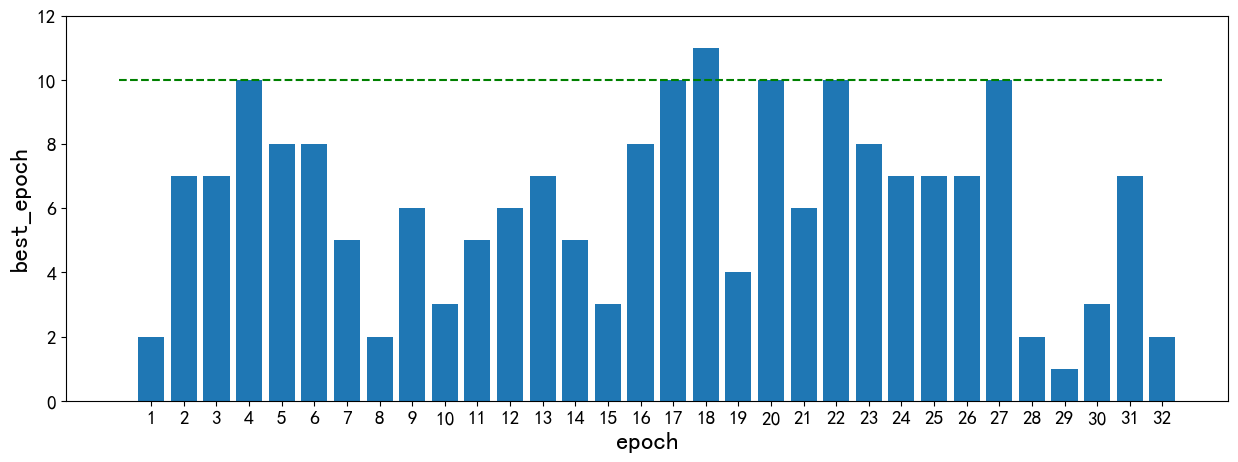

In [42]:
plt.figure(figsize=(15,5), dpi=100)
plt.rcParams['font.sans-serif']=['SimHei']
plt.bar(list(range(1,len(exec_result.query('n_gram==2'))+1)), np.array(exec_result.query('n_gram==2')['best_epoch'].values.tolist())+1)
plt.plot([0,32],[10,10],c='g',ls='--')
plt.xlabel('epoch', fontsize=18, fontweight='bold')
plt.ylabel('best_epoch', fontsize=18, fontweight='bold')
plt.xticks(range(1,len(exec_result.query('n_gram==2'))+1), fontsize=14)
plt.yticks(range(0,13,2),fontsize=14)
plt.show()

#### 动量对结果的影响

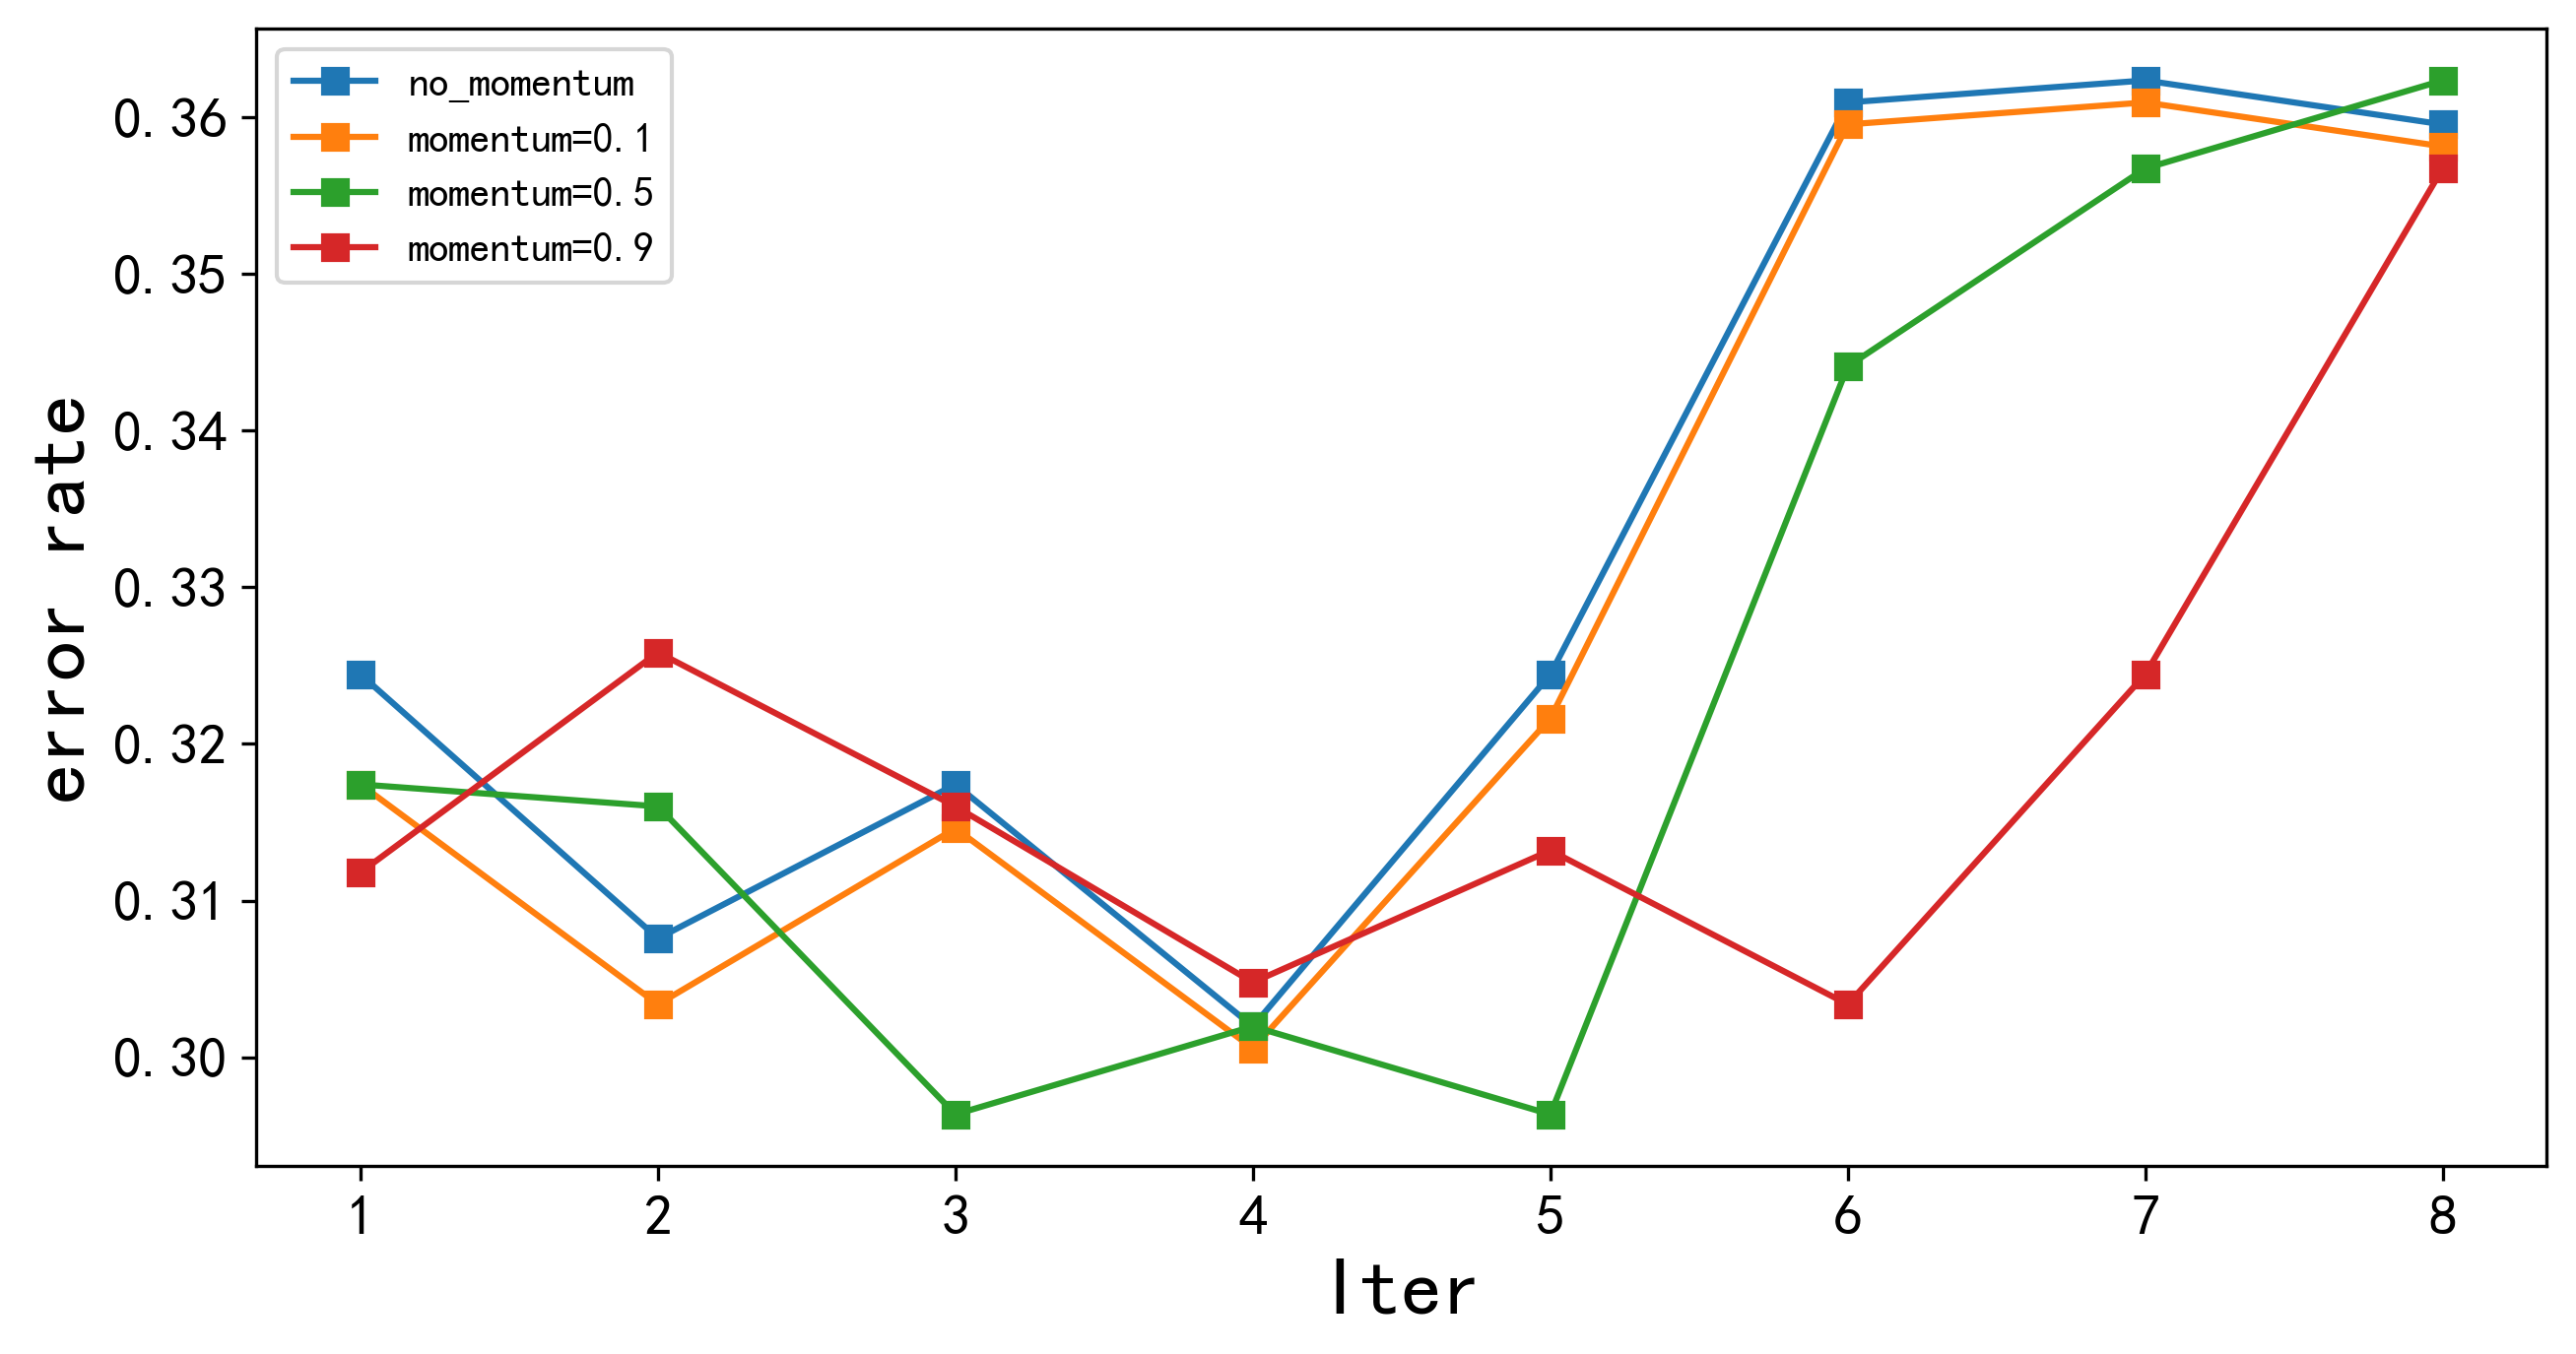

In [14]:
no_momentum = exec_result.query('use_momentum==False & n_gram==2')
momentum_01 = exec_result.query('momentum==0.1 & n_gram==2')
momentum_05 = exec_result.query('momentum==0.5 & n_gram==2')
momentum_09 = exec_result.query('momentum==0.9 & n_gram==2')
plt.figure(figsize=(10,5), dpi=300)
plt.rcParams['font.sans-serif']=['SimHei']
plt.plot(range(1,len(no_momentum)+1), no_momentum['best_errors_val'].values.tolist(), marker='s', label='no_momentum')
plt.plot(range(1,len(no_momentum)+1), momentum_01['best_errors_val'].values.tolist(), marker='s', label='momentum=0.1')
plt.plot(range(1,len(no_momentum)+1), momentum_05['best_errors_val'].values.tolist(), marker='s', label='momentum=0.5')
plt.plot(range(1,len(no_momentum)+1), momentum_09['best_errors_val'].values.tolist(), marker='s', label='momentum=0.9')
plt.xlabel('Iter', fontsize=20, fontweight='bold')
plt.ylabel('error rate', fontsize=20, fontweight='bold')
plt.xticks(range(1,len(no_momentum)+1), fontsize=14)
plt.yticks(fontsize=14)
plt.legend()
plt.show()

#### 学习率对结果的影响

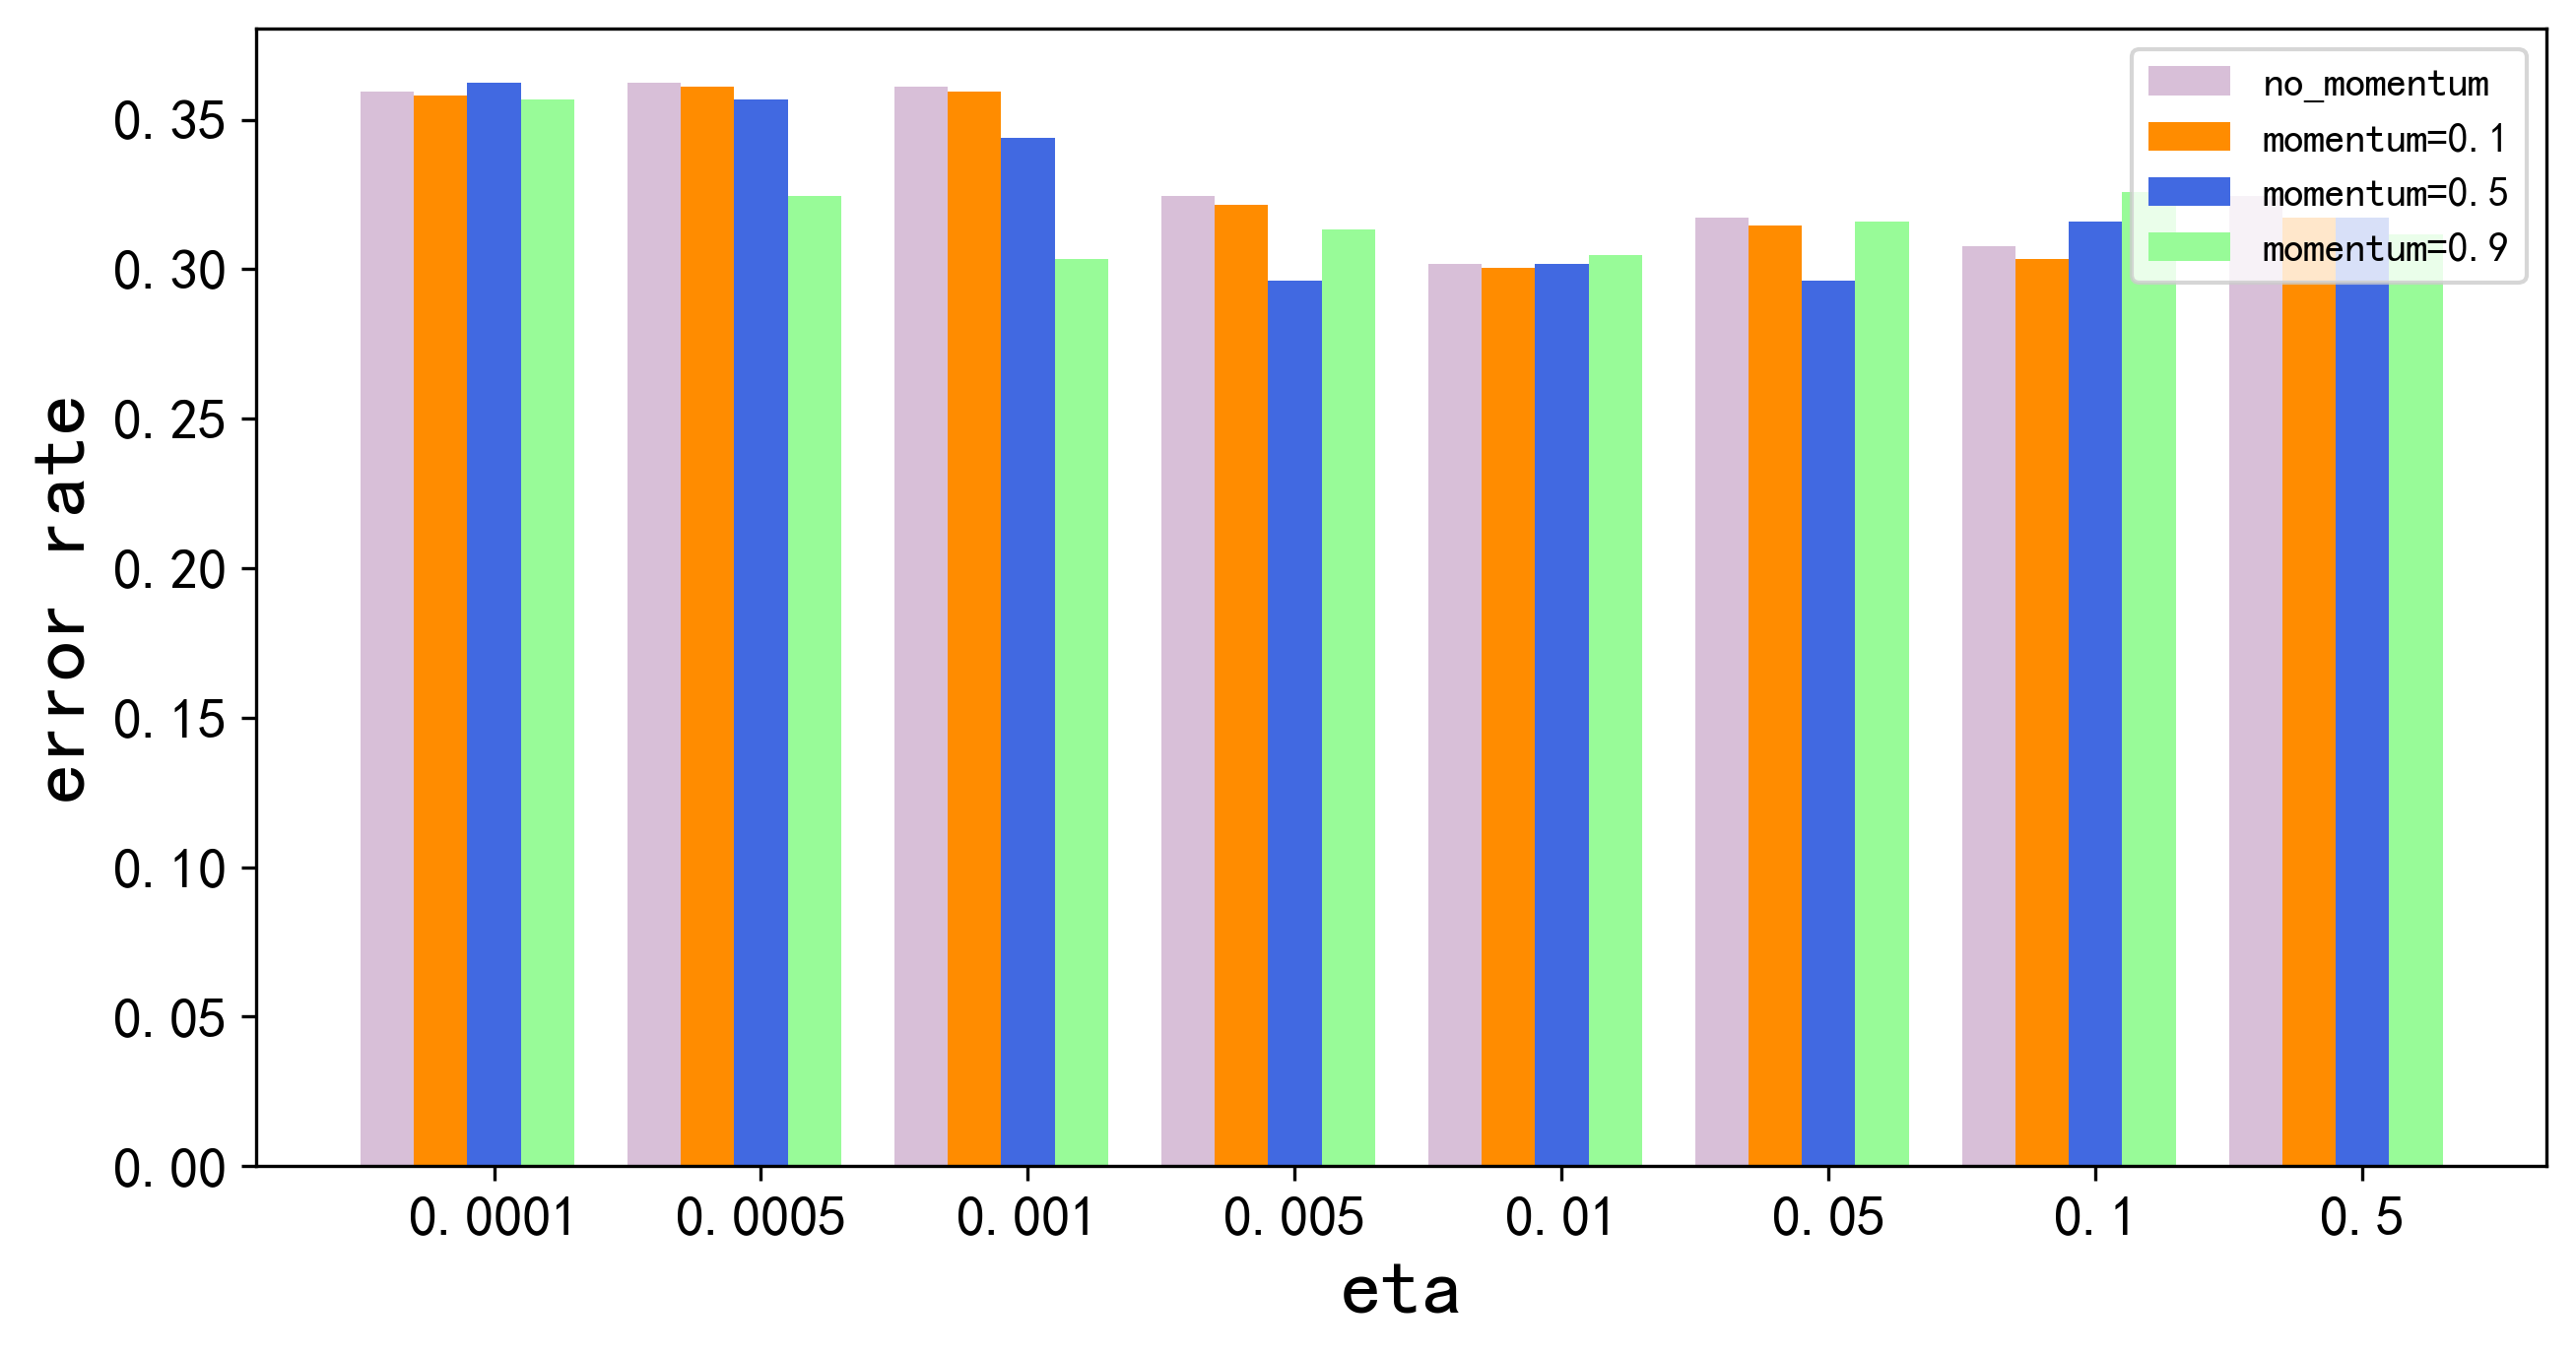

In [15]:
no_momentum = exec_result.query('use_momentum==False & n_gram==2')
momentum_01 = exec_result.query('momentum==0.1 & n_gram==2')
momentum_05 = exec_result.query('momentum==0.5 & n_gram==2')
momentum_09 = exec_result.query('momentum==0.9 & n_gram==2')
plt.figure(figsize=(10,5), dpi=300)
plt.rcParams['font.sans-serif']=['SimHei']

plt.bar(np.array(range(0,len(no_momentum['eta'])))+0.6, no_momentum['best_errors_val'].values.tolist()[::-1], width=0.2, color='thistle', label='no_momentum')
plt.bar(np.array(range(0,len(no_momentum['eta'])))+0.8, momentum_01['best_errors_val'].values.tolist()[::-1], width=0.2, color='darkorange', label='momentum=0.1')
plt.bar(np.array(range(0,len(no_momentum['eta'])))+1.0, momentum_05['best_errors_val'].values.tolist()[::-1], width=0.2, color='royalblue', label='momentum=0.5')
plt.bar(np.array(range(0,len(no_momentum['eta'])))+1.2, momentum_09['best_errors_val'].values.tolist()[::-1], width=0.2, color='palegreen', label='momentum=0.9')

plt.xlabel('eta', fontsize=20, fontweight='bold')
plt.ylabel('error rate', fontsize=20, fontweight='bold')
plt.xticks([1,2,3,4,5,6,7,8],[0.0001, 0.0005, 0.001, 0.005, 0.01, 0.05, 0.1, 0.5], fontsize=14)
plt.yticks(fontsize=14)
plt.legend()
plt.show()

In [16]:
no_momentum['best_errors_val'].values.tolist()[::-1]

[0.3595505617977528,
 0.36235955056179775,
 0.3609550561797753,
 0.324438202247191,
 0.30196629213483145,
 0.31741573033707865,
 0.30758426966292135,
 0.324438202247191]

### 最佳模型

In [36]:
# 取最佳模型
best_index = exec_result['best_errors_val'].idxmin()  
best_result = exec_result.iloc[best_index]
best_result

model                                                         n_gram
epochs                                                            12
eta                                                            0.005
use_momentum                                                    True
momentum                                                         0.5
n_gram                                                             2
best_epoch                                                        10
best_errors_val                                             0.296348
best_weights       {('die', 'another'): 1.2143064331837648e-17, (...
losses_train       [0.9669680492547289, 0.7267197971624189, 0.537...
losses_val         [0.9186489842665146, 0.8685210343830708, 0.839...
errors_train       [0.14133833646028768, 0.09255784865540963, 0.0...
errors_val         [0.3595505617977528, 0.34831460674157305, 0.35...
Name: 17, dtype: object

### loss和error rate可视化

In [19]:
def visualization(losses_train, losses_val, errors_train, errors_val):
    plt.figure(figsize=(14,5), dpi=150)
    plt.rcParams['font.sans-serif']=['SimHei']
    plt.subplot(121)
    plt.plot(range(1,len(losses_train)+1), losses_train, marker='s', label='train')
    plt.plot(range(1,len(losses_val)+1), losses_val, marker='s', label='val')
    plt.xlabel('epoch', fontsize=18, fontweight='bold')
    plt.ylabel('loss', fontsize=18, fontweight='bold')
    plt.xticks(range(2,len(errors_train)+1,2), fontsize=14)
    plt.yticks(fontsize=14)
    plt.legend()
    plt.subplot(122)
    plt.plot(range(1,len(errors_train)+1), errors_train, marker='s', label='train')
    plt.plot(range(1,len(errors_val)+1), errors_val, marker='s', label='val')
    plt.xlabel('epoch', fontsize=20, fontweight='bold')
    plt.ylabel('error rate', fontsize=20, fontweight='bold')
    plt.xticks(range(2,len(errors_train)+1,2), fontsize=14)
    plt.yticks(fontsize=14)
    plt.legend()
    plt.show()

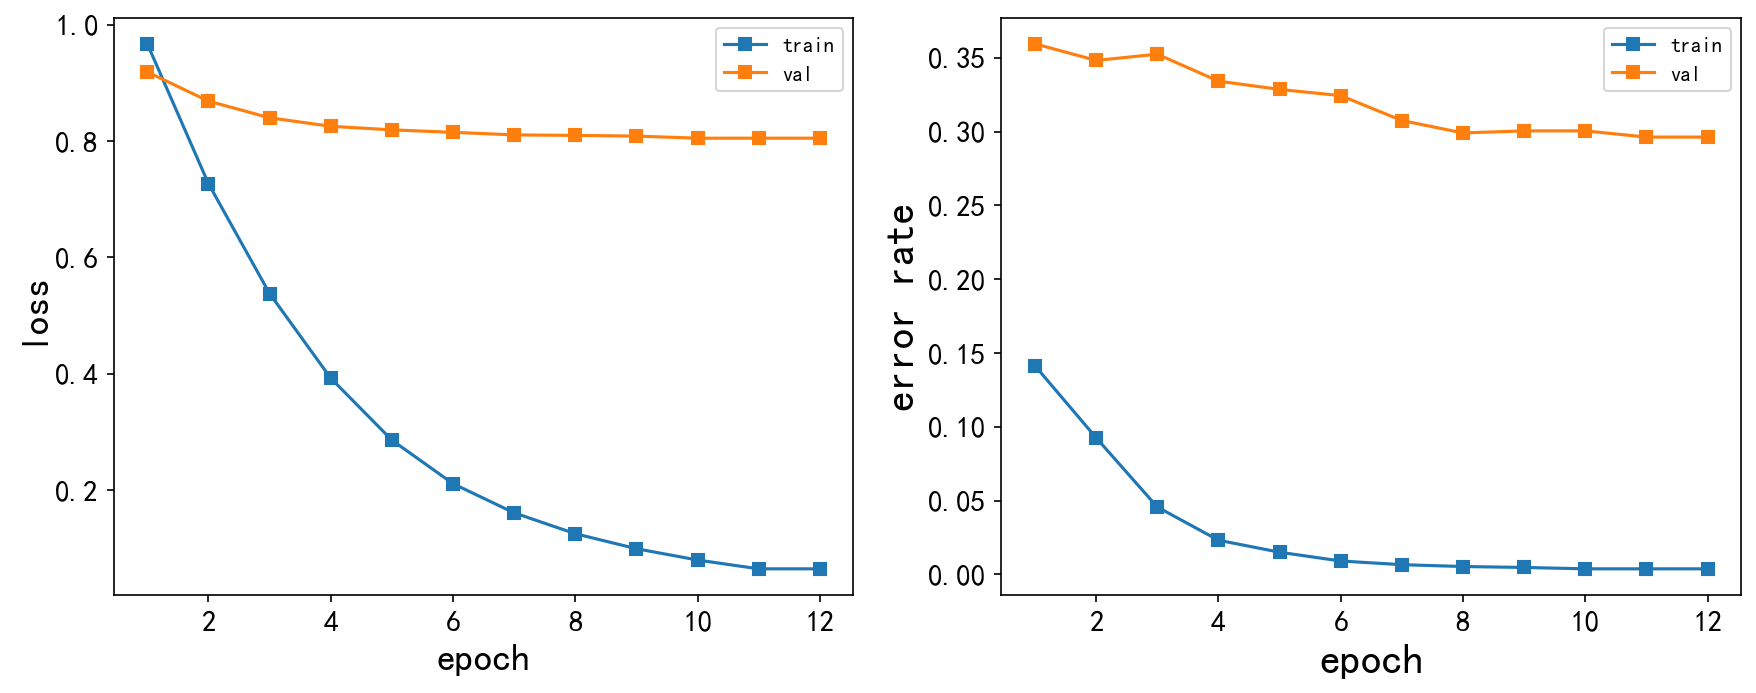

In [40]:
visualization(best_result.losses_train, 
              best_result.losses_val,
              best_result.errors_train,
              best_result.errors_val)

### 测试模型

In [44]:
# 取验证集上最好结果的权重来测试
weights = best_result.best_weights
trainError = evaluatePredictor(trainExamples, 
                               lambda x : (1 if dotProduct(featureExtractor(x), weights) >= 0 else -1))
testError = evaluatePredictor(testExamples, 
                              lambda x : (1 if dotProduct(featureExtractor(x), weights) >= 0 else -1))
print ("train error = %4f, validate error = %4f, test error = %4f" % (trainError, best_result.best_errors_val, testError)) 

train error = 0.029550, validate error = 0.296348, test error = 0.320826
